# Tracé de courbes à partir d'un ou plusieurs fichiers `.rpt`

Ce notebook permet de :
- Lire **un dossier complet** contenant plusieurs fichiers `.rpt` (ou un fichier `.rpt` unique).
- Détecter automatiquement les **blocs multiples** dans un fichier `.rpt` (cas typique d'Abaqus avec l'option *Append to file* activée) et ne garder que le dernier bloc si souhaité.
- Supprimer les segments plats à `y = 0`.
- Positionner / centrer l'origine du repère en `(0, 0)`.
- Tracer **un graphique global** et **un graphique individuel par fichier**.

## 1. Importation des bibliothèques

In [34]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# Affichage des graphiques directement dans le notebook
%matplotlib inline

## 2. Fonctions utilitaires (lecture multi-blocs `.rpt` et mise en forme des axes)

In [35]:
def lire_blocs_rpt(chemin_fichier):
    """Lit un fichier .rpt et sépare automatiquement les différents blocs de données
    (séparés par un en-tête texte ou par un retour en arrière de l'abscisse X).
    """
    blocs = []
    bloc_courant = []
    x_precedent = None

    with open(chemin_fichier, "r", encoding="utf-8", errors="ignore") as f:
        for ligne in f:
            ligne = ligne.strip()
            if not ligne:
                continue
            morceaux = ligne.split()
            try:
                valeurs = [float(val.replace(",", ".")) for val in morceaux]
                if len(valeurs) < 2:
                    raise ValueError
            except ValueError:
                # En-tête texte : si un bloc était en cours, on le clôt
                if bloc_courant:
                    blocs.append(np.array(bloc_courant))
                    bloc_courant = []
                    x_precedent = None
                continue

            # Retour en arrière sur X = début d'une nouvelle courbe dans le même fichier
            if x_precedent is not None and valeurs[0] < x_precedent:
                blocs.append(np.array(bloc_courant))
                bloc_courant = []

            bloc_courant.append(valeurs)
            x_precedent = valeurs[0]

    if bloc_courant:
        blocs.append(np.array(bloc_courant))

    if not blocs:
        raise ValueError(f"Aucune donnée numérique trouvée dans : {chemin_fichier}")

    return blocs


def lister_fichiers_rpt(chemin_entree, inclure_sous_dossiers=False):
    """Retourne la liste triée des fichiers .rpt à partir d'un dossier ou d'un fichier unique."""
    chemin = Path(chemin_entree)
    if not chemin.exists():
        raise FileNotFoundError(f"Chemin introuvable : {chemin}")

    if chemin.is_file():
        return [chemin]

    motif = "**/*.rpt" if inclure_sous_dossiers else "*.rpt"
    fichiers = sorted(chemin.glob(motif))
    if not fichiers:
        raise FileNotFoundError(f"Aucun fichier .rpt trouvé dans le dossier : {chemin}")
    return fichiers


def formater_graphique(ax, titre_graph, x_vals, y_vals):
    """Applique le titre, les échelles, l'origine en (0, 0), les bornes, la grille et la légende."""
    ax.set_title(titre_graph, fontsize=14, fontweight="bold", pad=16)
    ax.set_xscale(echelle_x)
    ax.set_yscale(echelle_y)

    if axes_en_zero and echelle_x == "linear" and echelle_y == "linear":
        ax.spines["left"].set_position("zero")
        ax.spines["bottom"].set_position("zero")
        ax.spines["right"].set_color("none")
        ax.spines["top"].set_color("none")
        ax.xaxis.set_ticks_position("bottom")
        ax.yaxis.set_ticks_position("left")

        if centrer_symetrique and x_vals and y_vals:
            max_x = max(np.max(np.abs(arr)) for arr in x_vals) * 1.05
            max_y = max(np.max(np.abs(arr)) for arr in y_vals) * 1.05
            ax.set_xlim(-max_x, max_x)
            ax.set_ylim(-max_y, max_y)
        else:
            xmin, xmax = ax.get_xlim()
            ymin, ymax = ax.get_ylim()
            ax.set_xlim(min(0, xmin), max(0, xmax))
            ax.set_ylim(min(0, ymin), max(0, ymax))

        ax.set_xlabel(label_x, fontsize=12, loc="right")
        ax.set_ylabel(label_y, fontsize=12, loc="top")
    else:
        ax.set_xlabel(label_x, fontsize=12)
        ax.set_ylabel(label_y, fontsize=12)

    if limites_x:
        ax.set_xlim(limites_x)
    if limites_y:
        ax.set_ylim(limites_y)

    ax.grid(True, which="both", linestyle="--", alpha=0.5)
    ax.legend(loc="best", frameon=True)

## 3. Paramètres à personnaliser

Indiquez dans `chemin_entree` l'adresse du **dossier** contenant vos fichiers `.rpt` (ou l'adresse d'un seul fichier `.rpt`).

In [36]:
# Chemin vers un DOSSIER contenant plusieurs .rpt OU vers un fichier .rpt unique
# Exemple Windows : r"C:\Users\Nom\Documents\mes_resultats_rpt"
chemin_entree = r"C:\Users\pacom\Documents\Cours\2026-2027\MIG\Export\SIGMAF"
inclure_sous_dossiers = False  # Passer à True pour chercher aussi dans les sous-dossiers

# Gestion des fichiers .rpt contenant plusieurs blocs empilés (ex: export Abaqus 'Append to file')
# - "dernier" : ne garde que le dernier bloc de chaque fichier (recommandé pour avoir 1 courbe/fichier)
# - "premier" : ne garde que le premier bloc de chaque fichier
# - "tous"    : trace tous les blocs séparément
mode_blocs_rpt = "dernier"

# Titre et noms des axes
titre = "Évolution de la contrainte en fonction du temps"
label_x = "Temps (s)"
label_y = "Contrainte (MPa)"

# Suppression du trait plat à y = 0
enlever_zeros_y = True
seuil_zero = 1e-12  # Les valeurs |y| <= seuil_zero ne seront pas tracées

# Repère centré / origine en (0, 0)
axes_en_zero = True          # Place les axes X et Y pour qu'ils se croisent en (0, 0)
centrer_symetrique = False   # Passer à True pour forcer (0, 0) au centre géométrique du graphique

# Échelles : "linear" ou "log" (axes_en_zero est actif uniquement en échelle "linear")
echelle_x = "linear"
echelle_y = "linear"

# Bornes manuelles des axes : (min, max) ou None pour un ajustement automatique
limites_x = None  # Exemple : (-10, 10) ou (0, 10)
limites_y = None  # Exemple : (-500, 500) ou (0, 500)

# Noms personnalisés dans la légende (optionnel : dict {"nom_fichier_sans_ext": "Légende"})
# Laissez {} pour utiliser automatiquement le nom de chaque fichier .rpt
noms_personnalises = {}

# Exports images
fichier_sortie_global = "courbes_rpt_global.png"
dossier_sortie_individuel = Path("courbes_individuelles")

## 4. Chargement et vérification des fichiers `.rpt`

In [37]:
fichiers_rpt = lister_fichiers_rpt(chemin_entree, inclure_sous_dossiers=inclure_sous_dossiers)
jeux_de_donnees = []

print(f"{len(fichiers_rpt)} fichier(s) .rpt trouvé(s) (mode_blocs_rpt = '{mode_blocs_rpt}') :")
for fichier in fichiers_rpt:
    blocs = lire_blocs_rpt(fichier)

    if mode_blocs_rpt == "dernier":
        blocs_retenus = [blocs[-1]]
    elif mode_blocs_rpt == "premier":
        blocs_retenus = [blocs[0]]
    elif mode_blocs_rpt == "tous":
        blocs_retenus = blocs
    else:
        raise ValueError("mode_blocs_rpt doit être 'dernier', 'premier' ou 'tous'.")

    for idx, data in enumerate(blocs_retenus):
        nom = fichier.stem if len(blocs_retenus) == 1 else f"{fichier.stem}_bloc{idx + 1}"
        jeux_de_donnees.append((nom, data))

    print(f"  - {fichier.name} : {len(blocs)} bloc(s) détecté(s) -> {len(blocs_retenus)} retenu(s) ({blocs_retenus[-1].shape[0]} lignes, {blocs_retenus[-1].shape[1]} colonnes)")

37 fichier(s) .rpt trouvé(s) (mode_blocs_rpt = 'dernier') :
  - SIGMAF_centri_00.rpt : 1 bloc(s) détecté(s) -> 1 retenu(s) (43 lignes, 2 colonnes)
  - SIGMAF_centri_01.rpt : 1 bloc(s) détecté(s) -> 1 retenu(s) (43 lignes, 2 colonnes)
  - SIGMAF_centri_02.rpt : 1 bloc(s) détecté(s) -> 1 retenu(s) (25 lignes, 2 colonnes)
  - SIGMAF_centri_03.rpt : 2 bloc(s) détecté(s) -> 1 retenu(s) (26 lignes, 2 colonnes)
  - SIGMAF_centri_04.rpt : 3 bloc(s) détecté(s) -> 1 retenu(s) (28 lignes, 2 colonnes)
  - SIGMAF_centri_05.rpt : 4 bloc(s) détecté(s) -> 1 retenu(s) (31 lignes, 2 colonnes)
  - SIGMAF_centri_06.rpt : 5 bloc(s) détecté(s) -> 1 retenu(s) (29 lignes, 2 colonnes)
  - SIGMAF_centri_07.rpt : 6 bloc(s) détecté(s) -> 1 retenu(s) (30 lignes, 2 colonnes)
  - SIGMAF_centri_08.rpt : 7 bloc(s) détecté(s) -> 1 retenu(s) (30 lignes, 2 colonnes)
  - SIGMAF_centri_09.rpt : 8 bloc(s) détecté(s) -> 1 retenu(s) (30 lignes, 2 colonnes)
  - SIGMAF_centri_10.rpt : 9 bloc(s) détecté(s) -> 1 retenu(s) (29 lig

## 5. Graphique global : toutes les courbes superposées

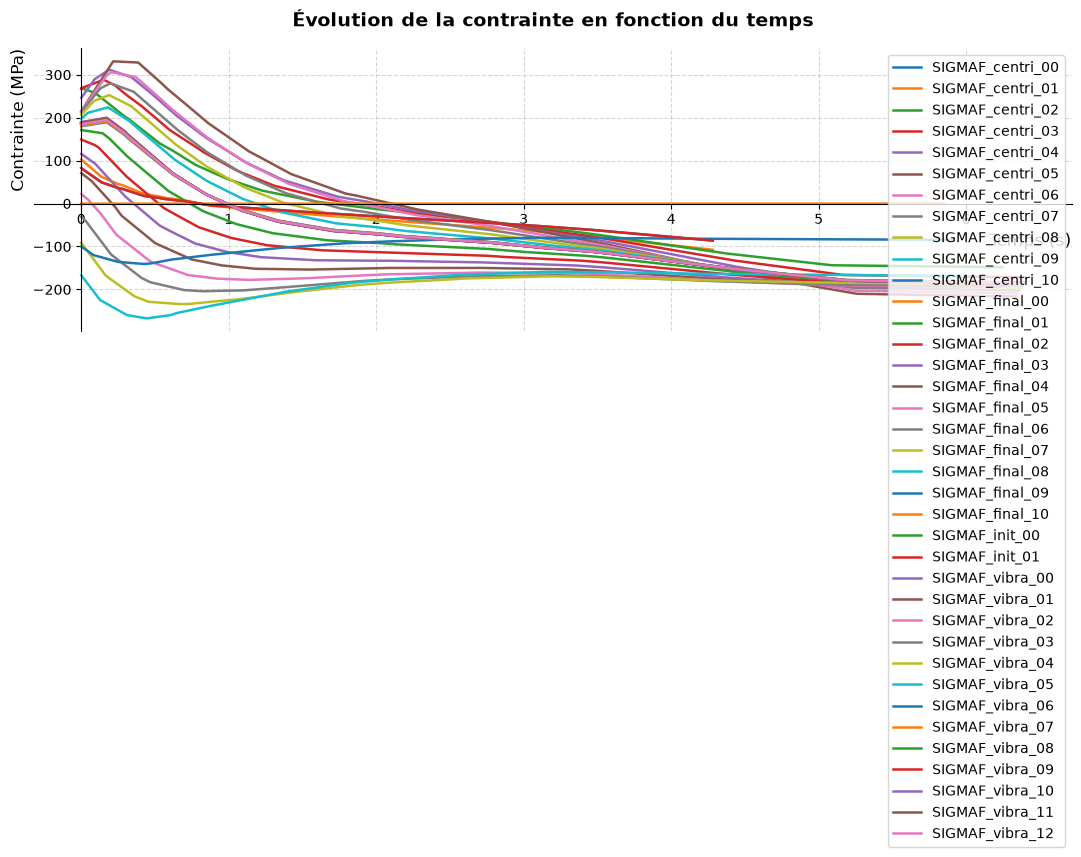

In [38]:
fig, ax = plt.subplots(figsize=(11, 6.5))

tous_x = []
tous_y = []

for nom_fichier, data in jeux_de_donnees:
    x = data[:, 0]
    colonnes_y = data[:, 1:]
    nom_base = noms_personnalises.get(nom_fichier, nom_fichier)

    for i in range(colonnes_y.shape[1]):
        y = colonnes_y[:, i].astype(float).copy()
        if enlever_zeros_y:
            y[np.abs(y) <= seuil_zero] = np.nan

        label = nom_base if colonnes_y.shape[1] == 1 else f"{nom_base} - Courbe {i + 1}"
        ax.plot(x, y, linewidth=1.8, label=label)

        valides = ~np.isnan(y)
        if np.any(valides):
            tous_x.append(x[valides])
            tous_y.append(y[valides])

formater_graphique(ax, titre, tous_x, tous_y)

plt.tight_layout()
plt.savefig(fichier_sortie_global, dpi=300)
plt.show()
plt.close(fig)

## 6. Graphiques individuels : une seule courbe par graphique

Chaque courbe est tracée sur sa propre figure isolée et enregistrée dans le dossier `courbes_individuelles/`.

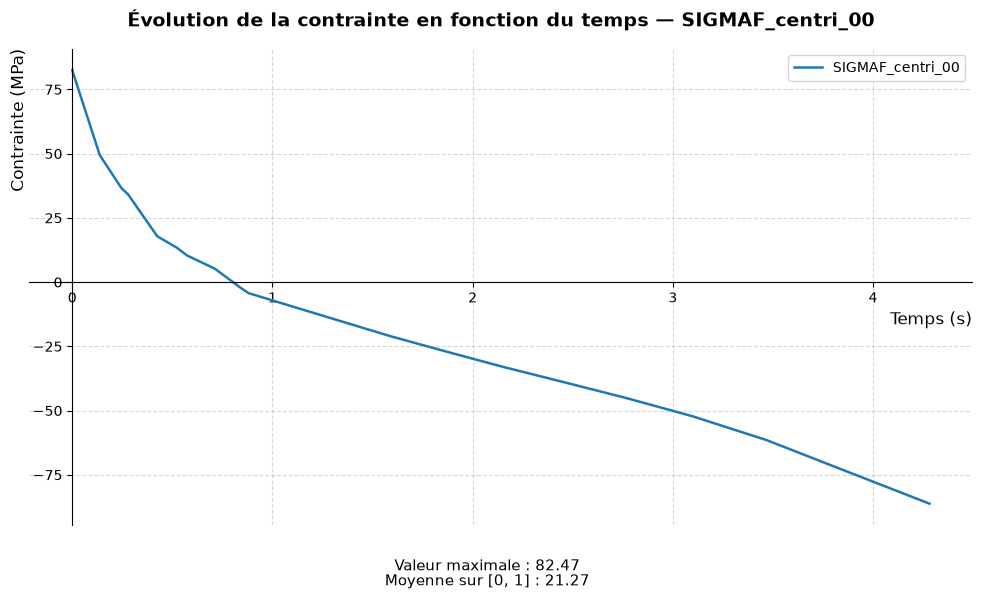

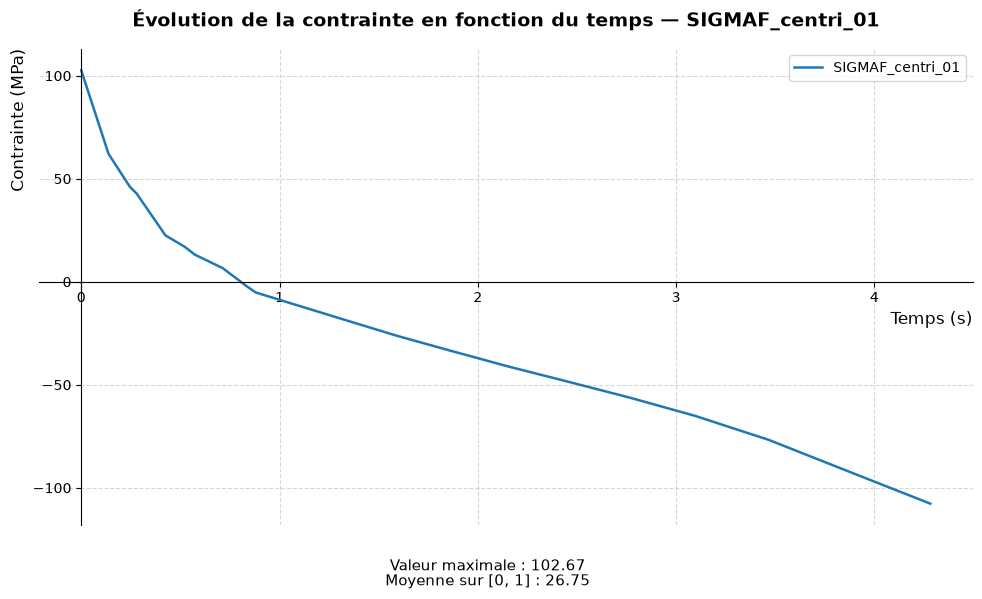

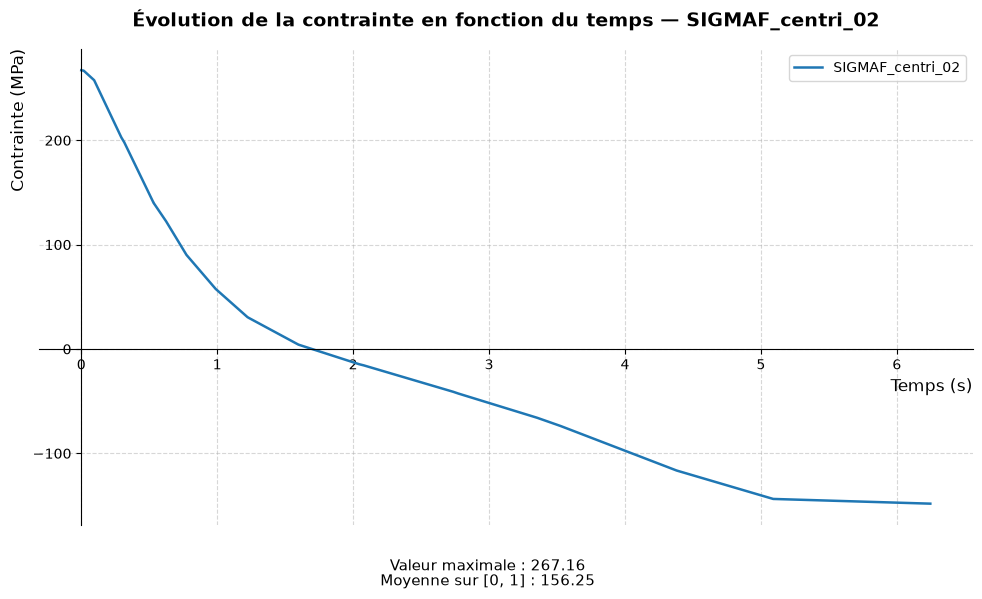

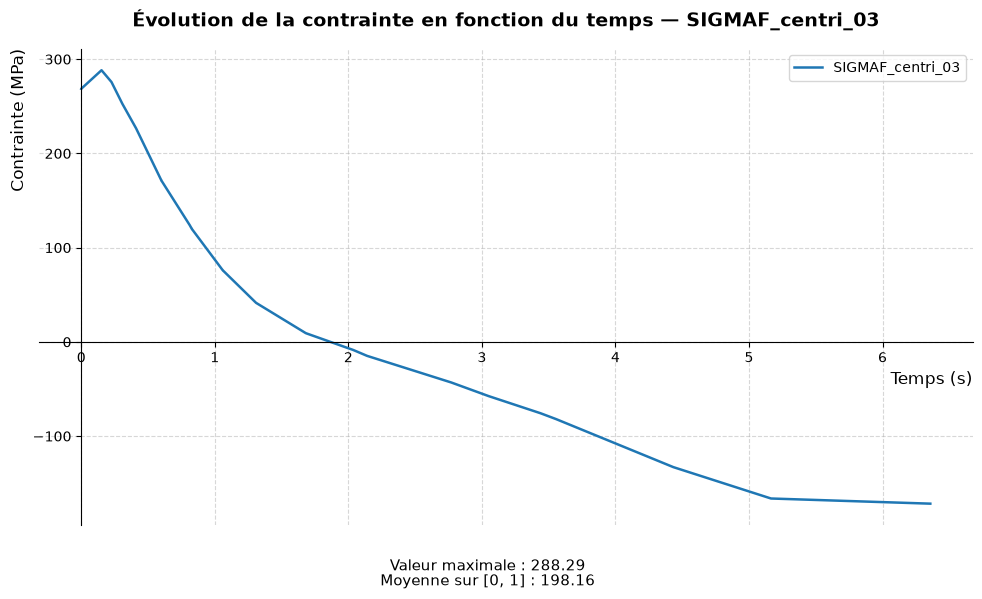

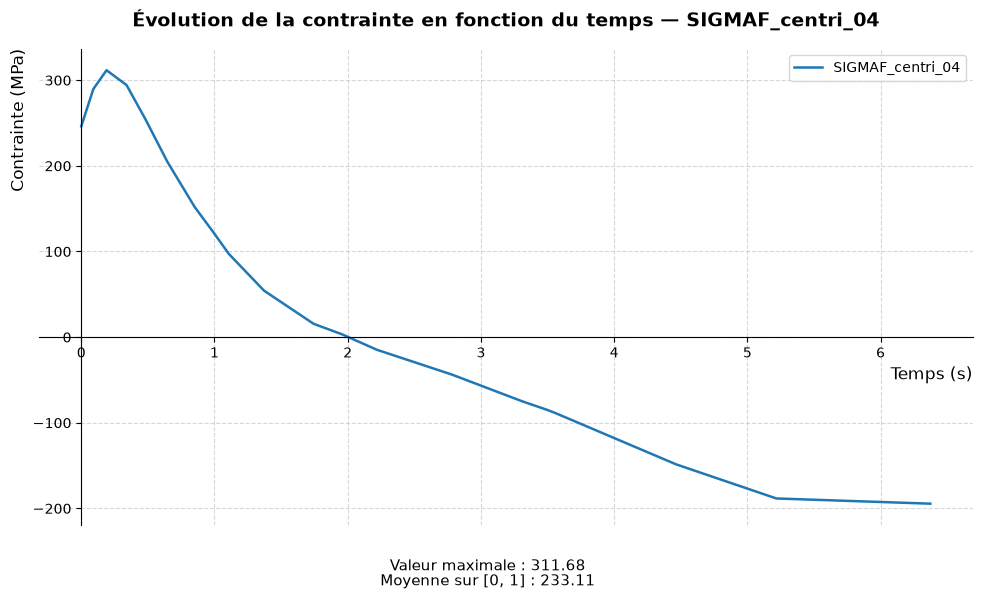

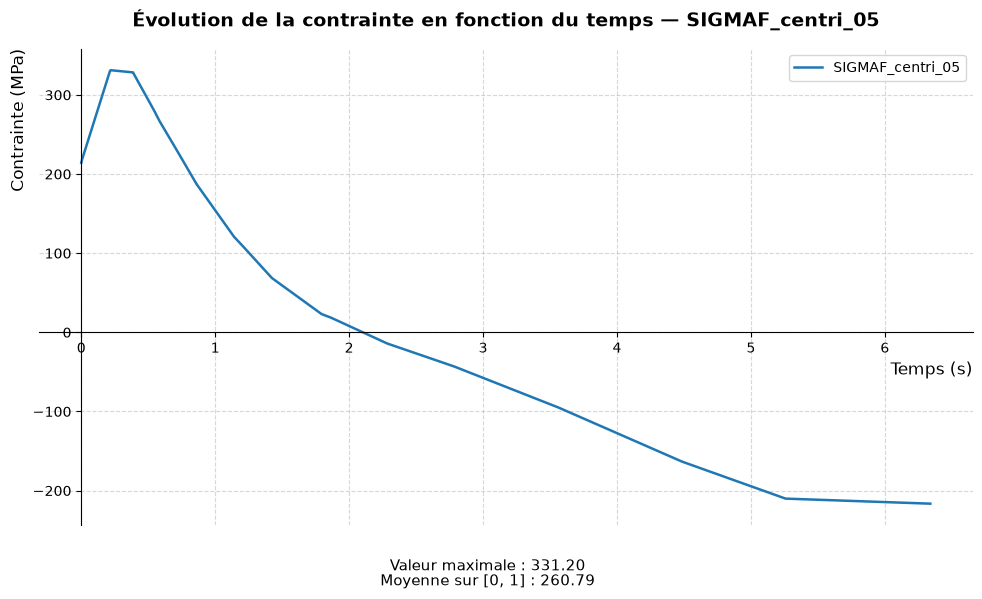

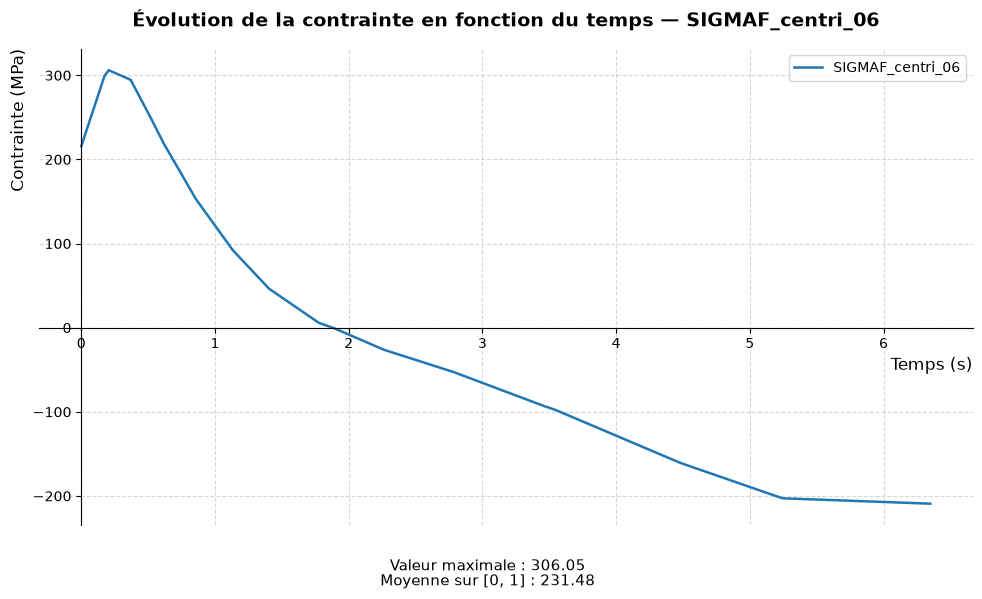

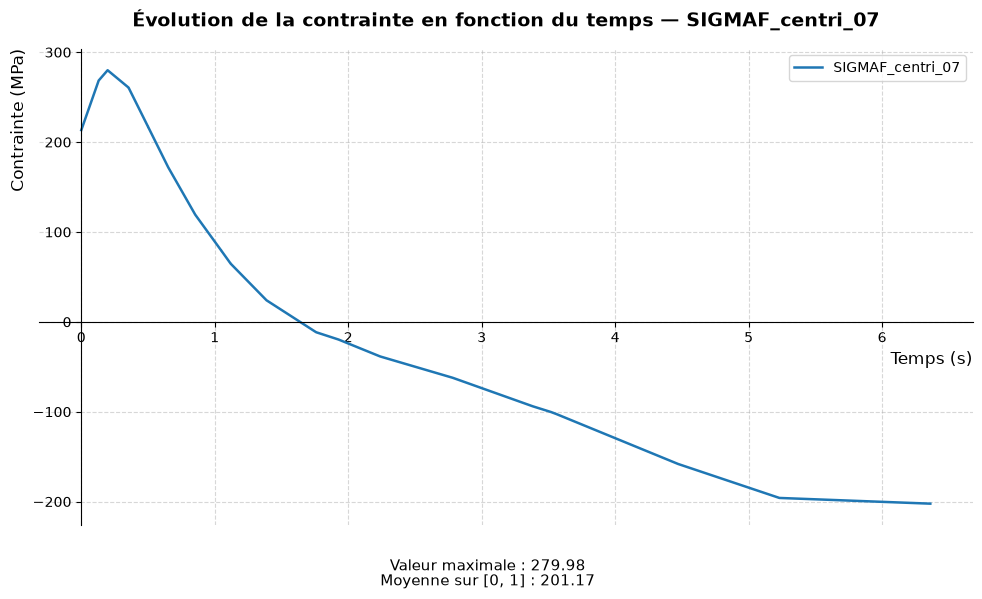

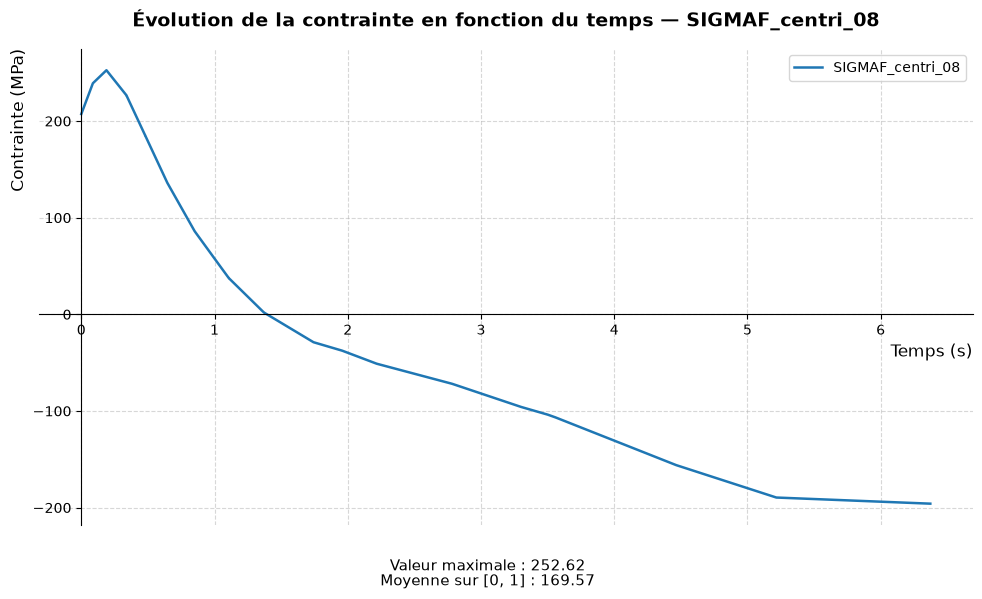

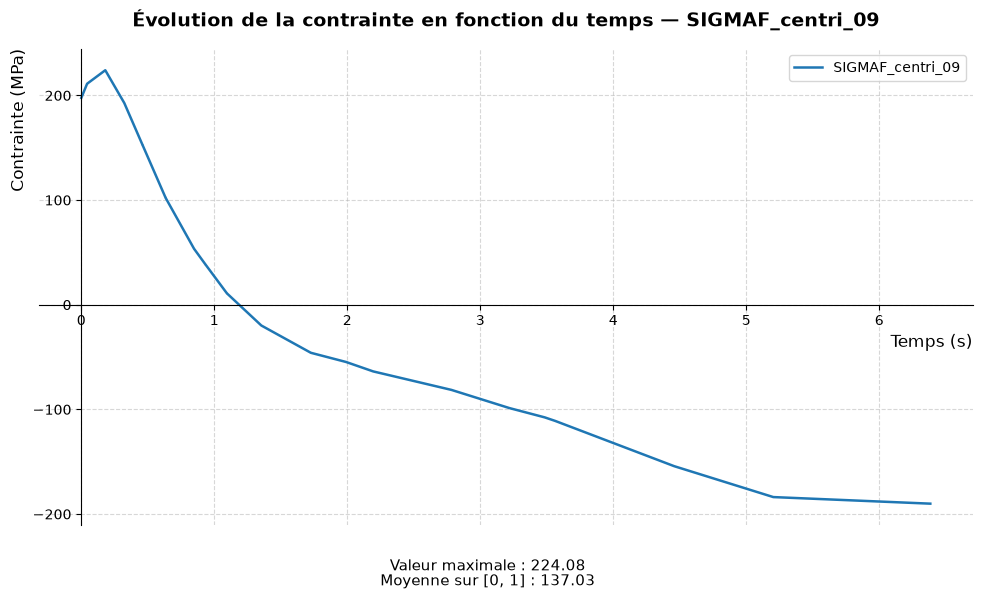

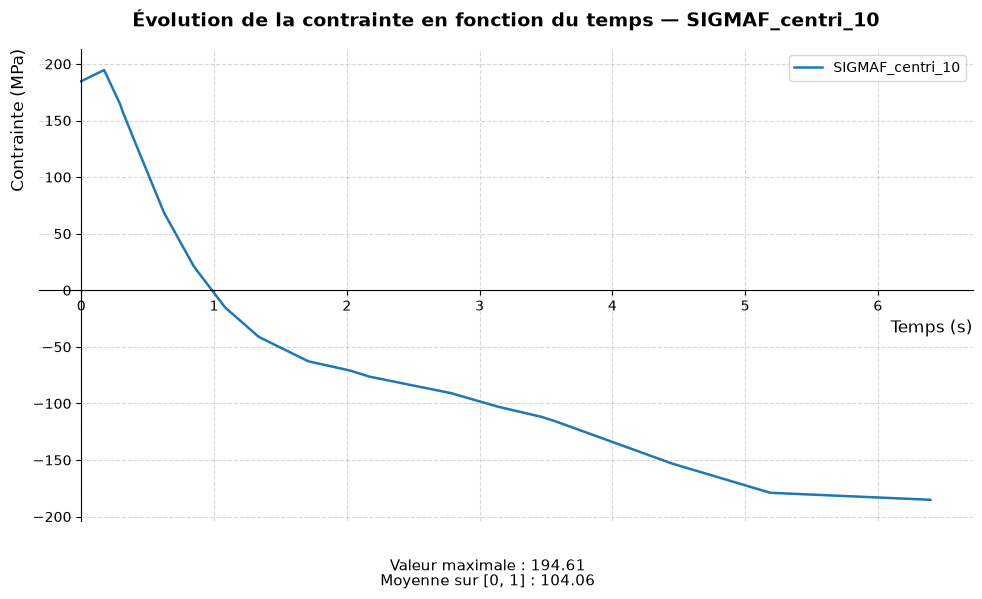

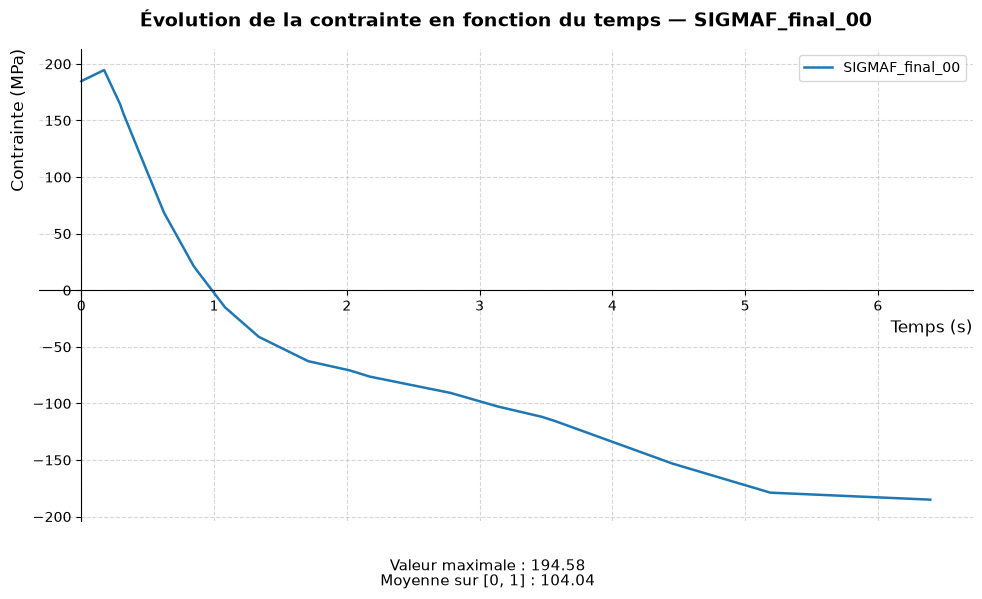

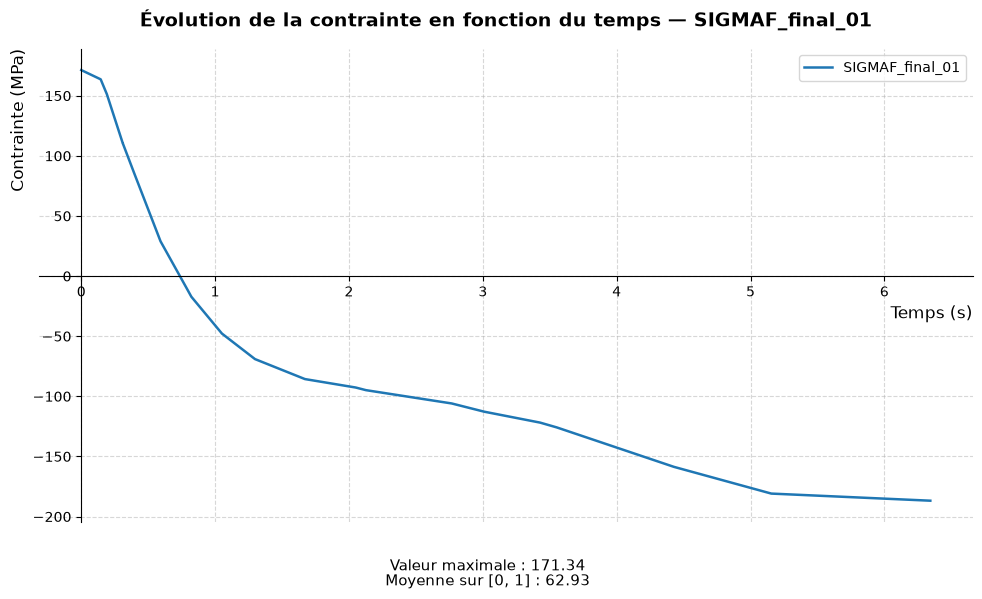

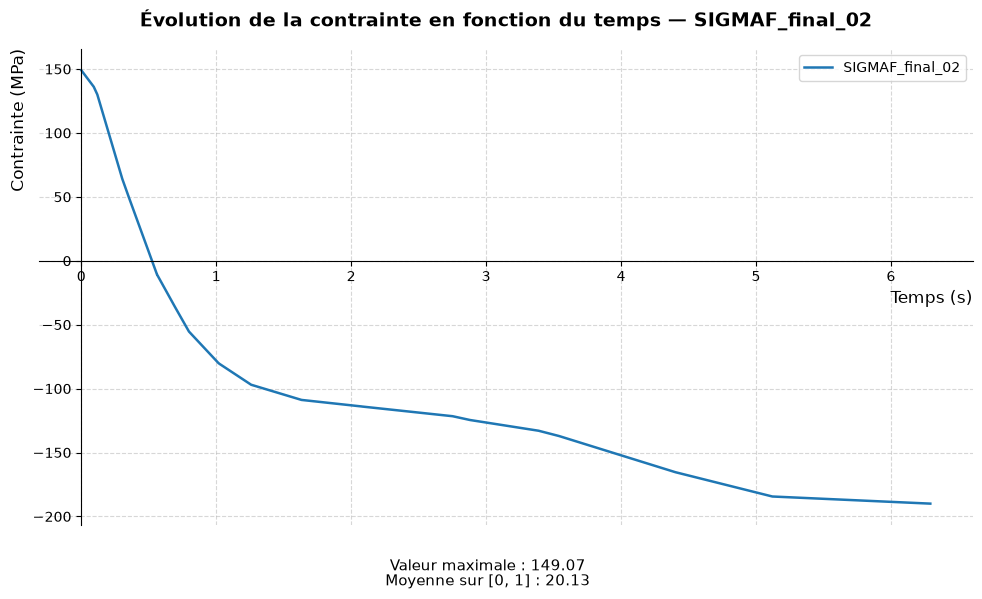

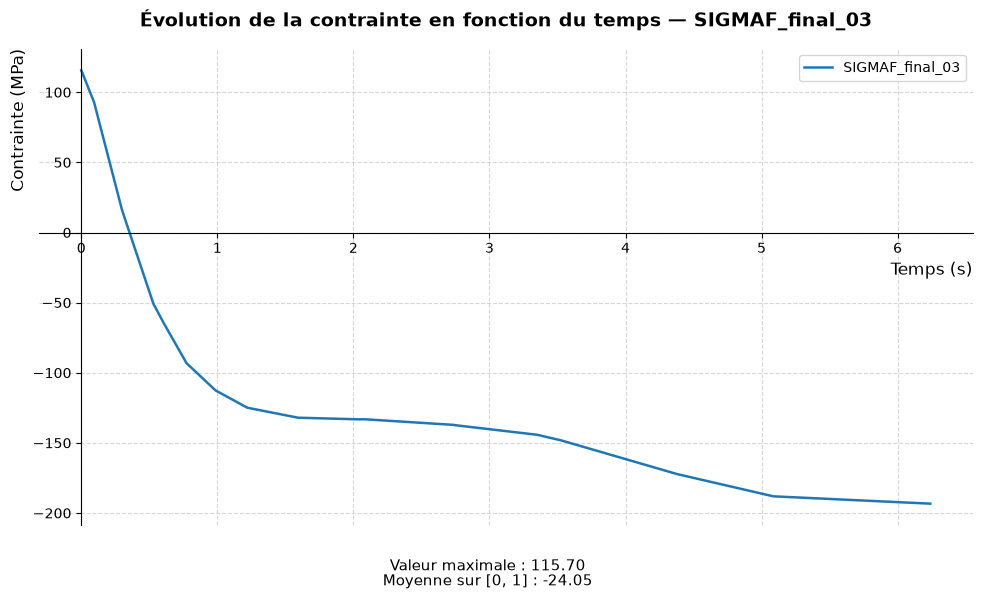

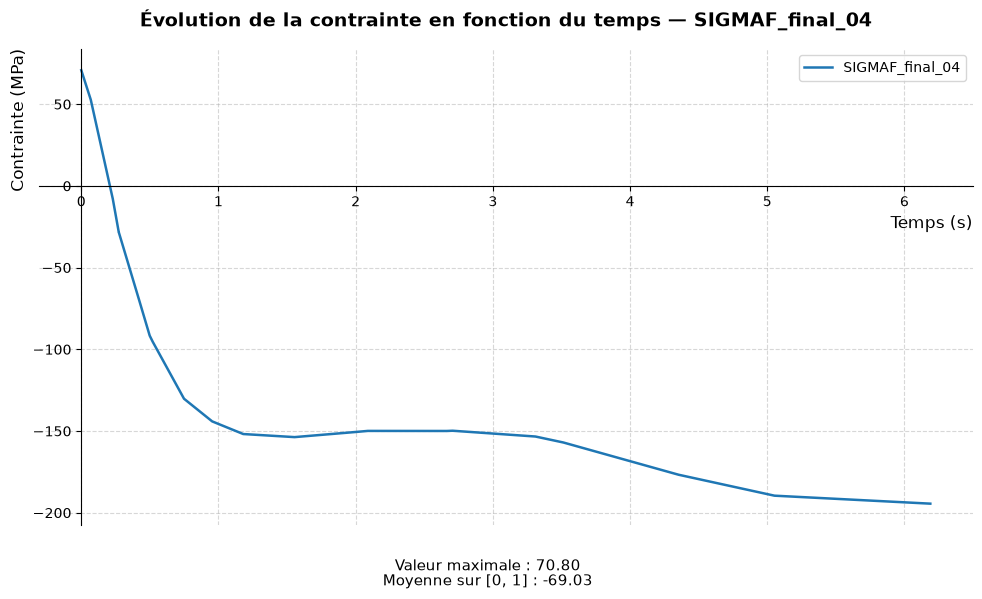

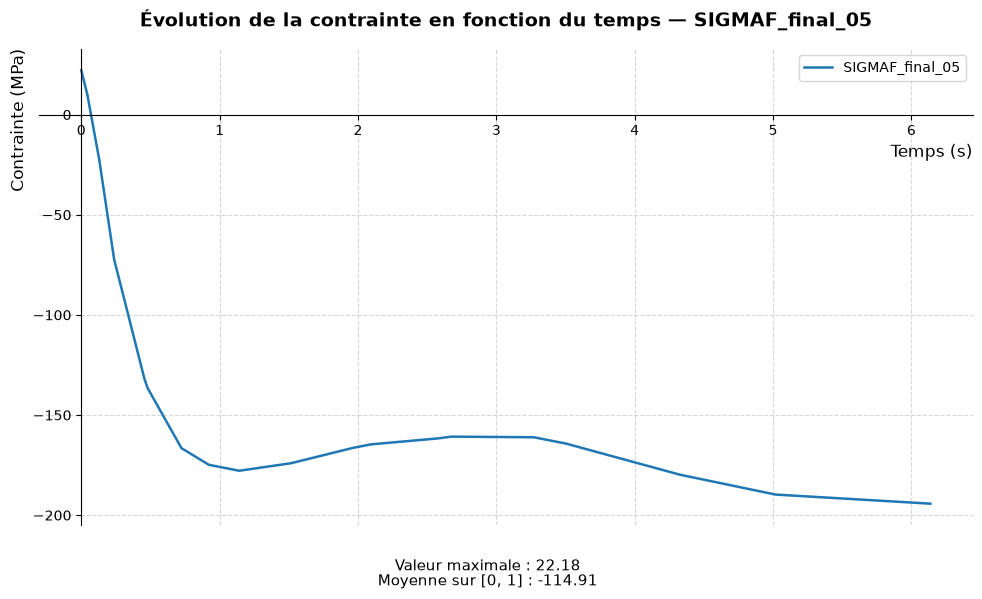

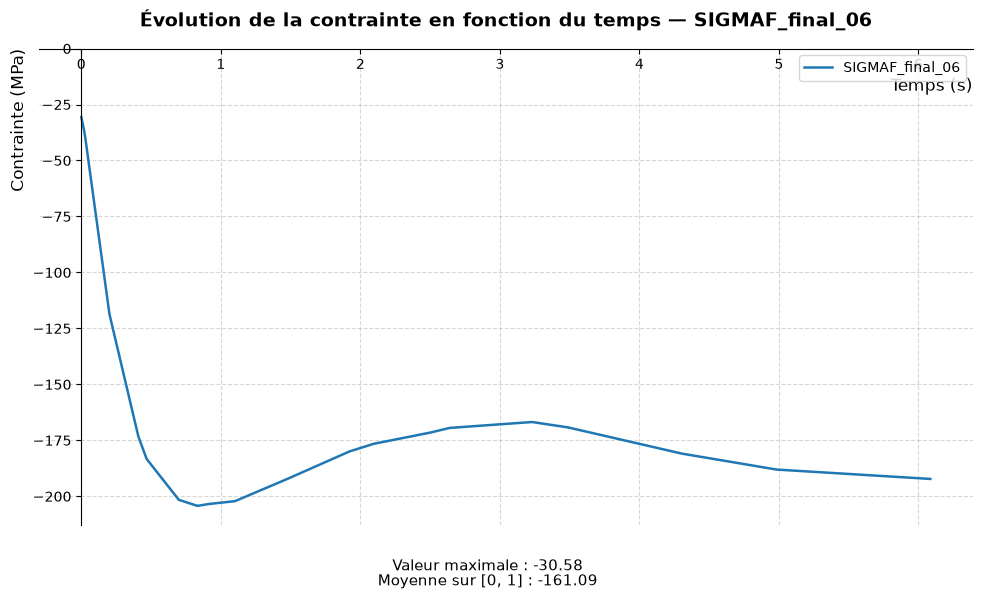

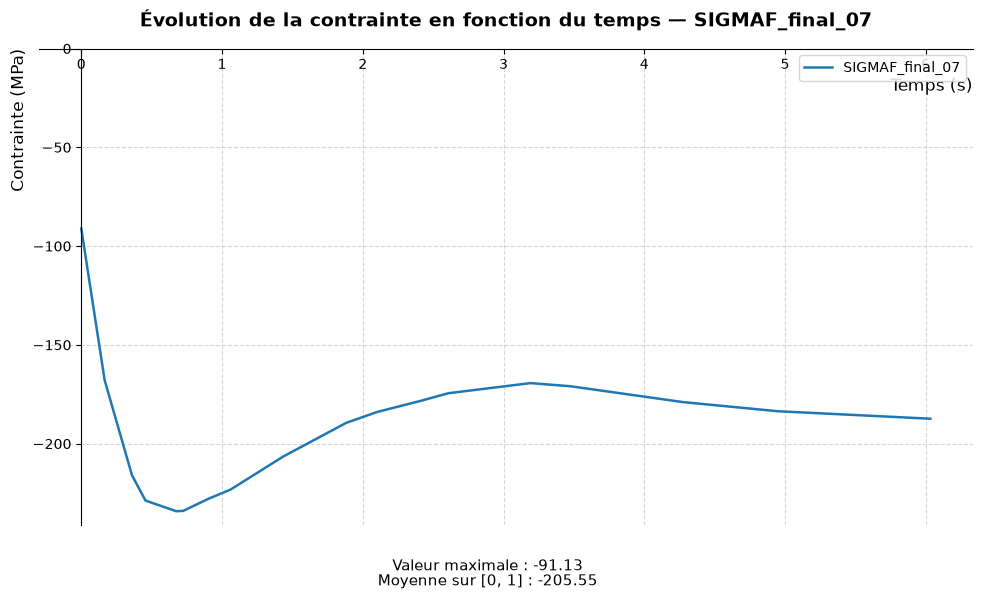

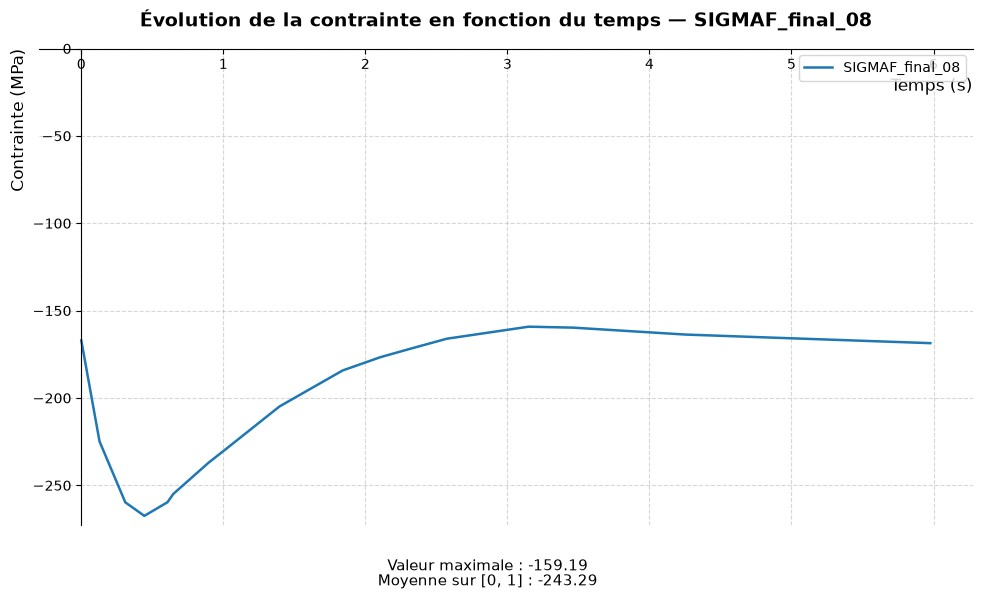

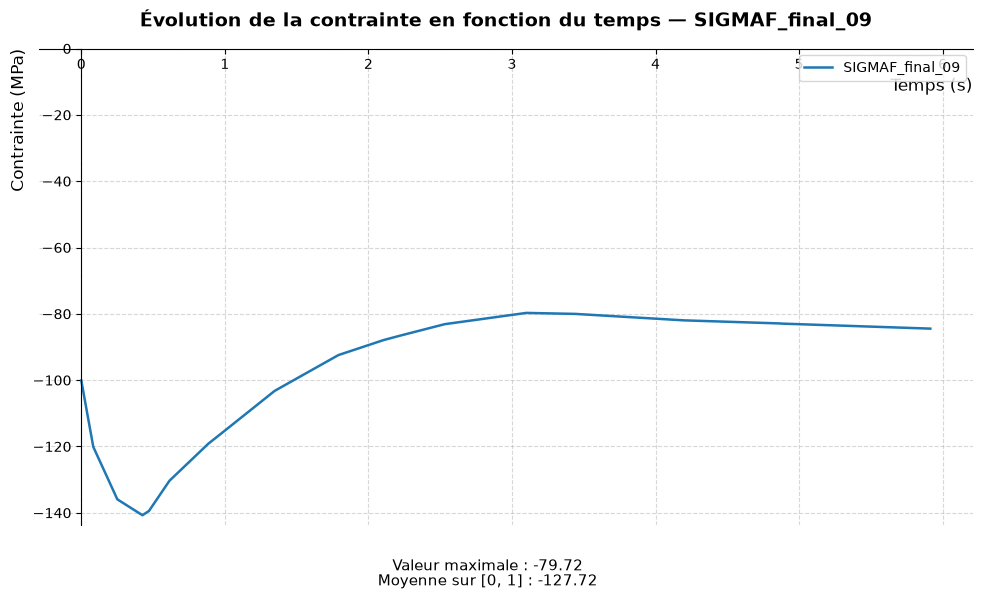

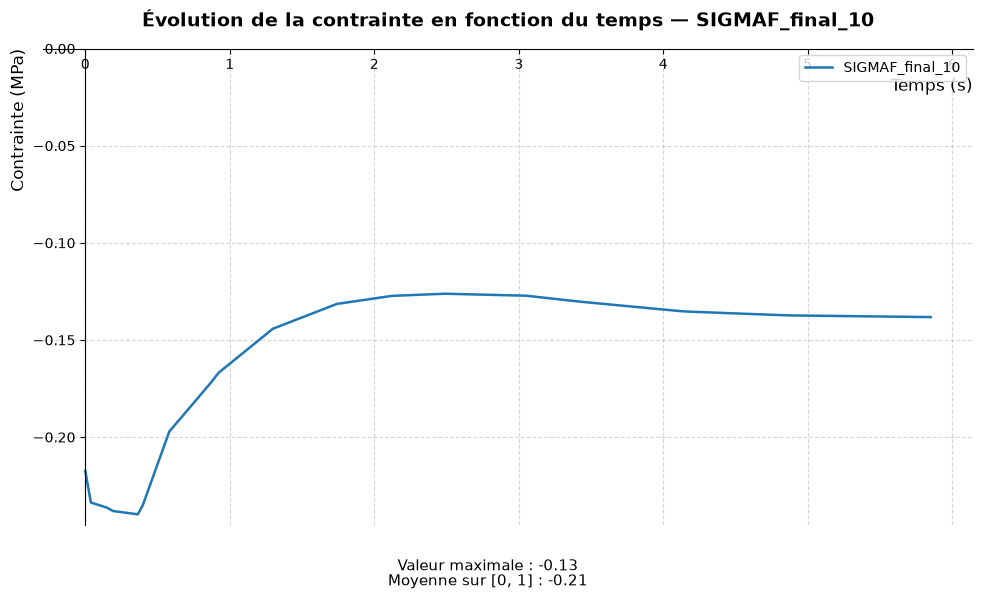

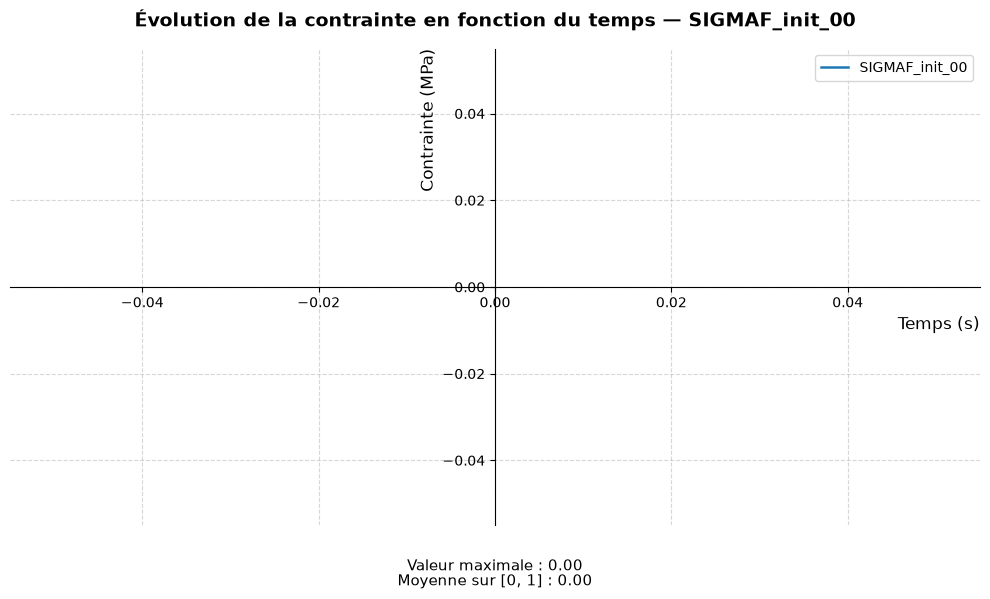

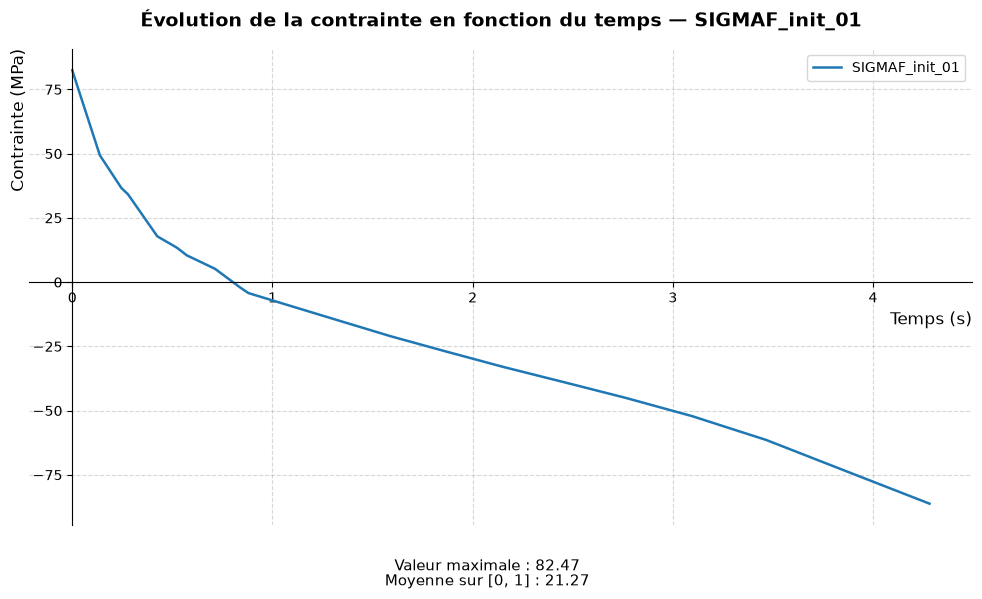

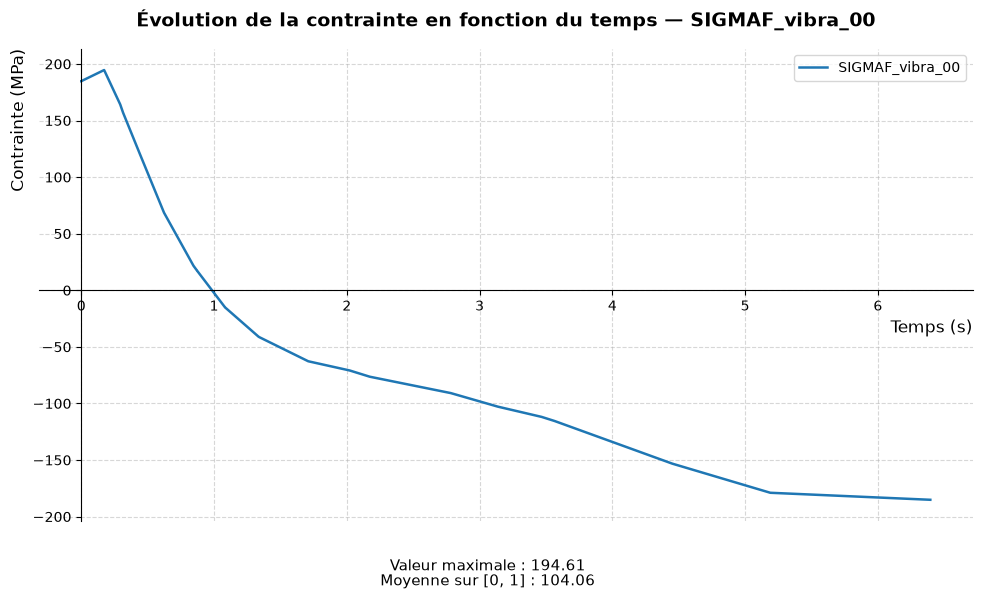

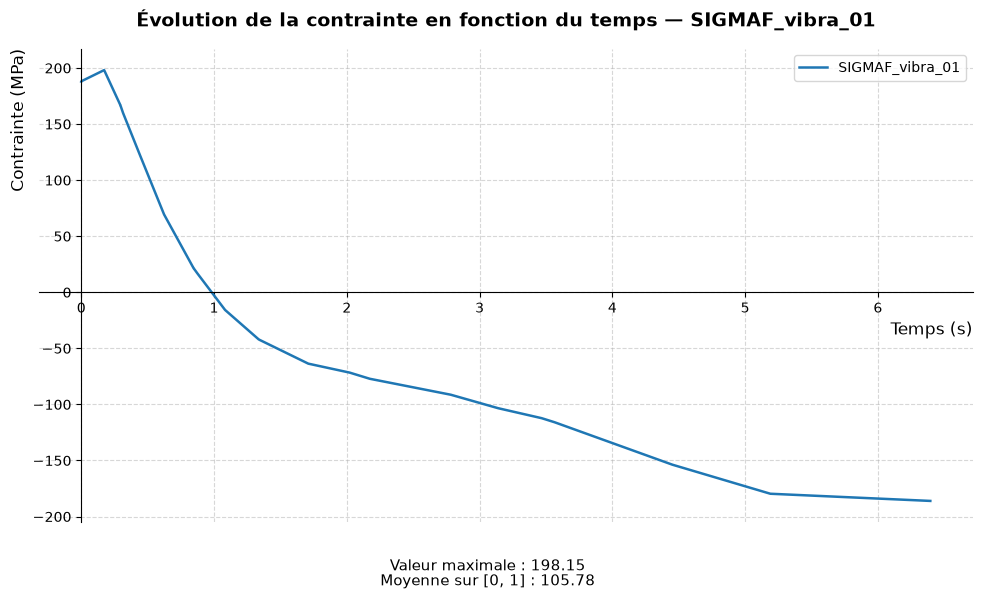

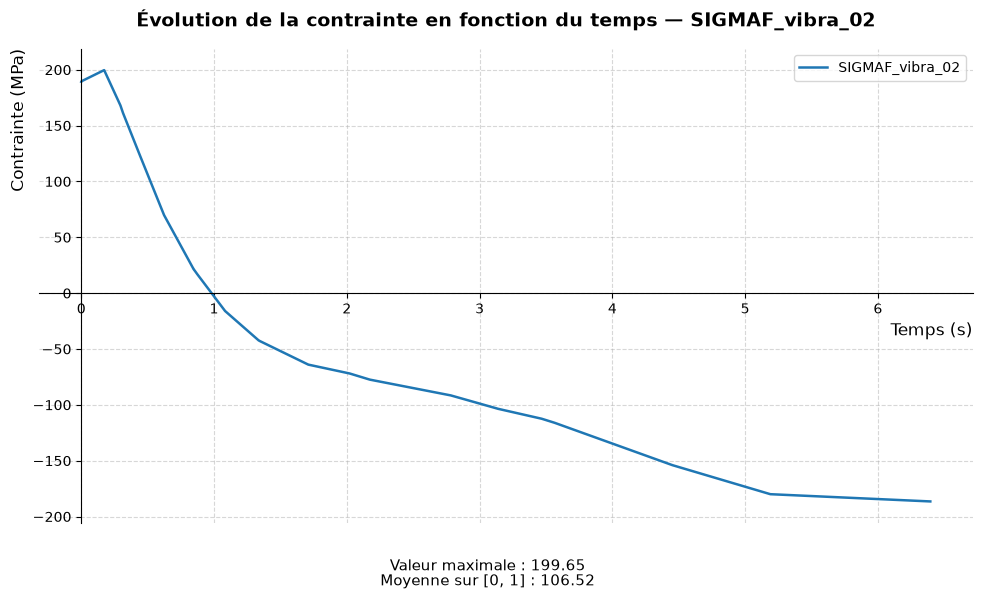

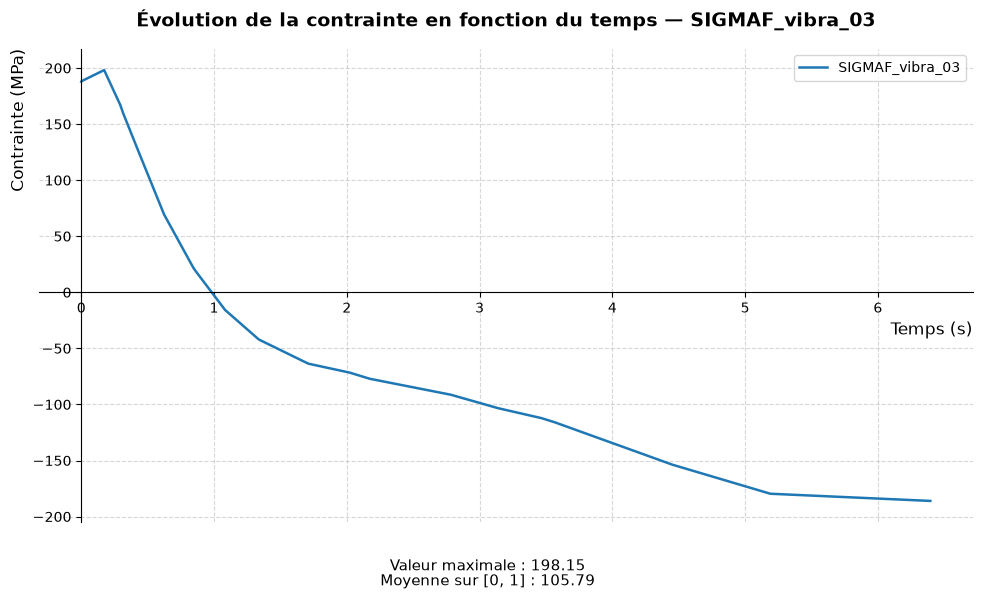

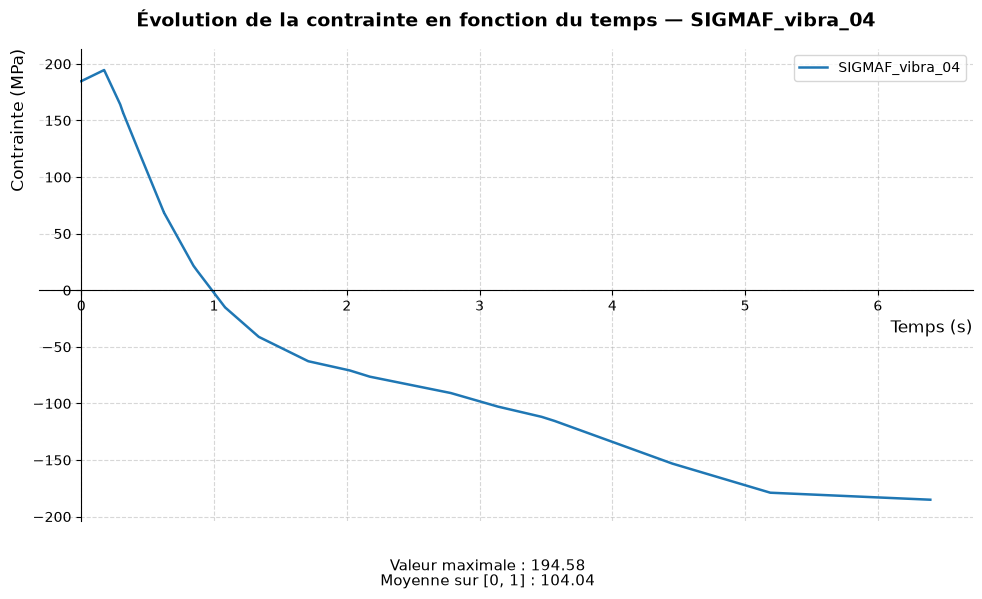

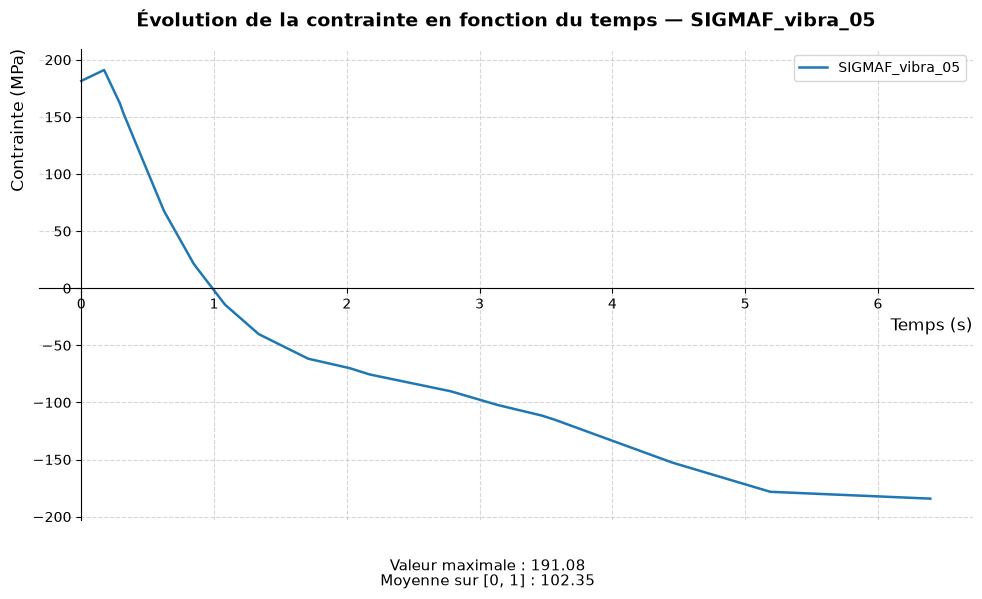

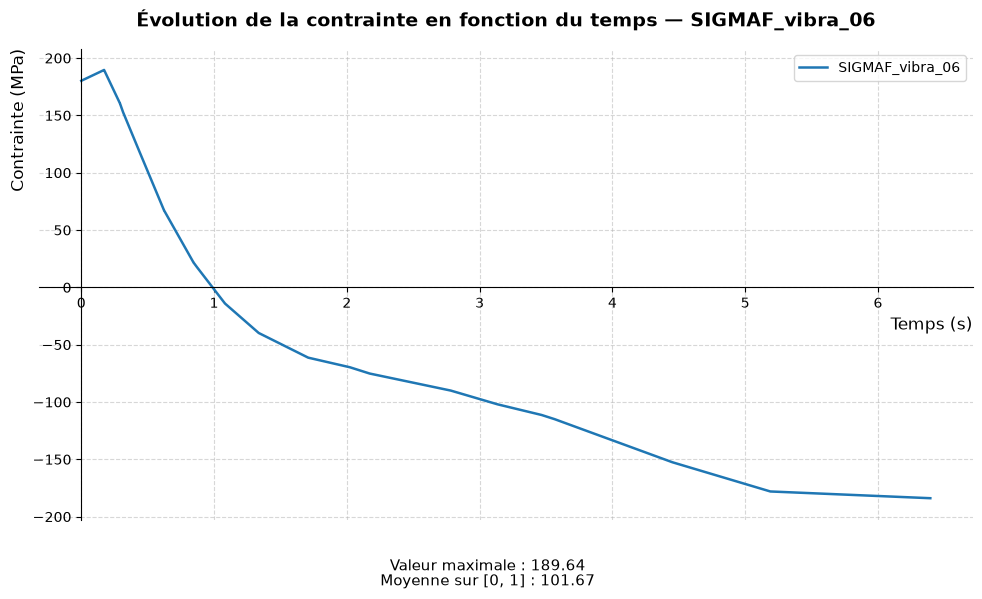

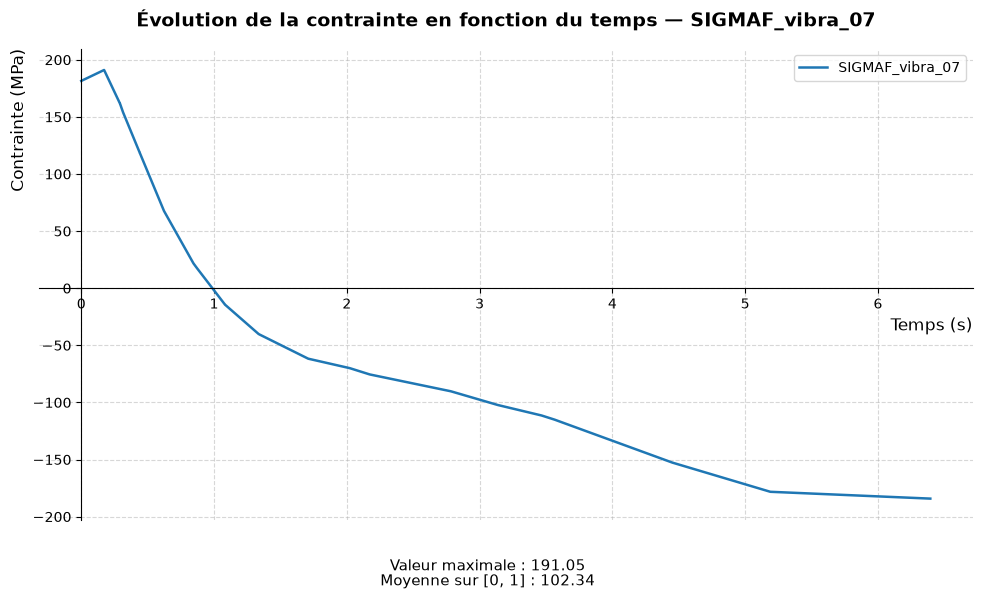

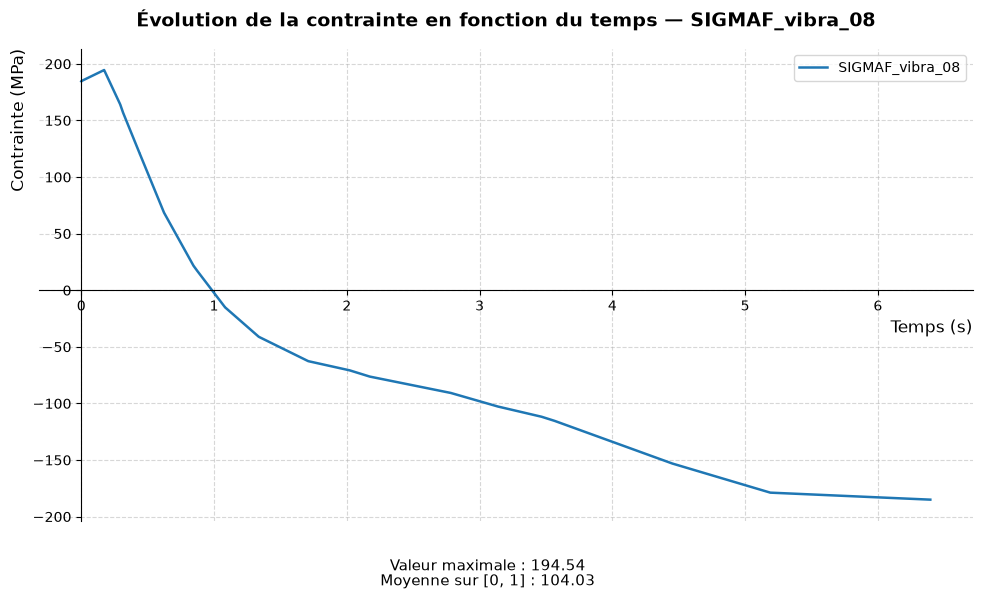

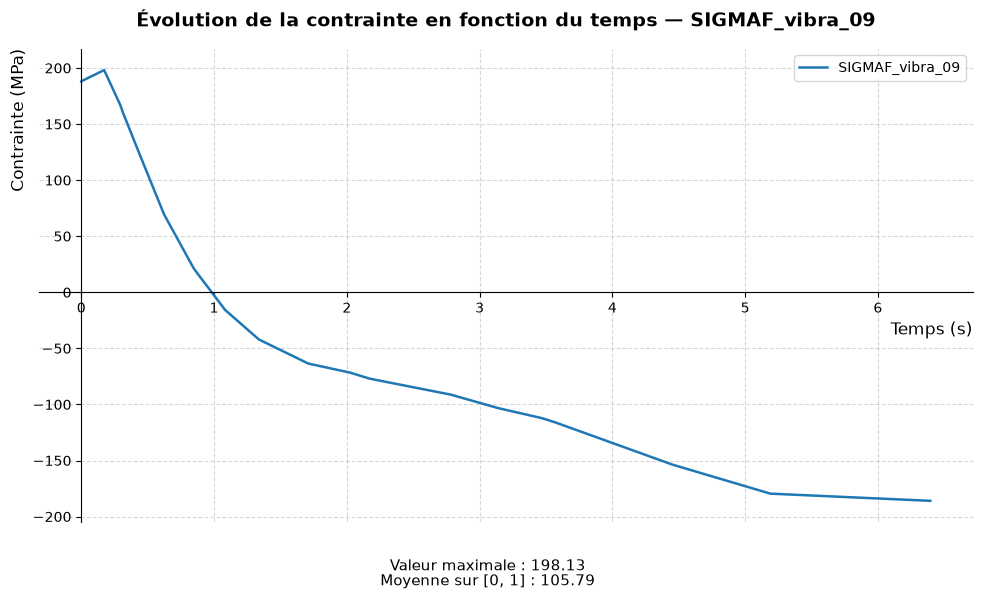

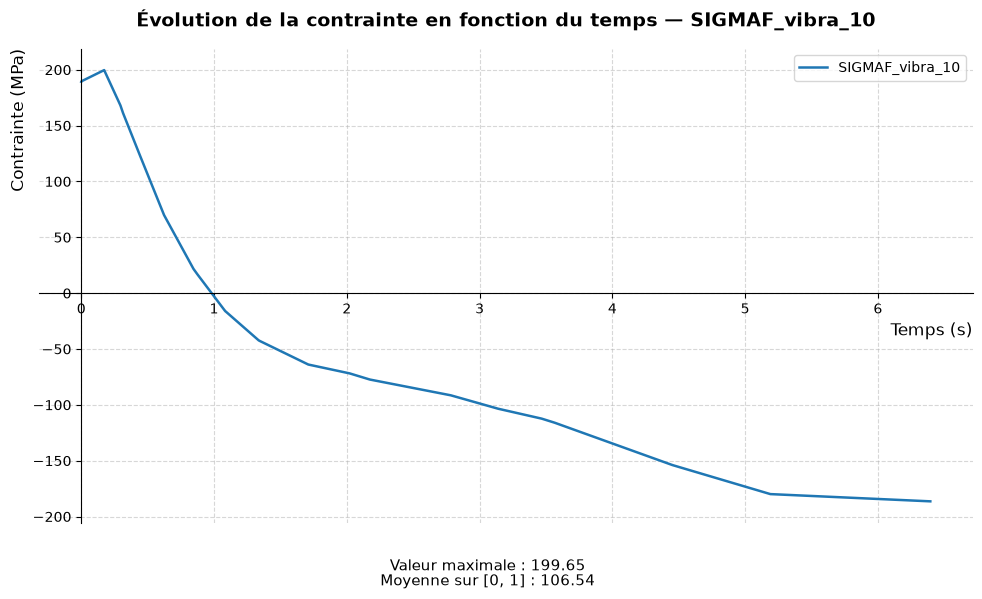

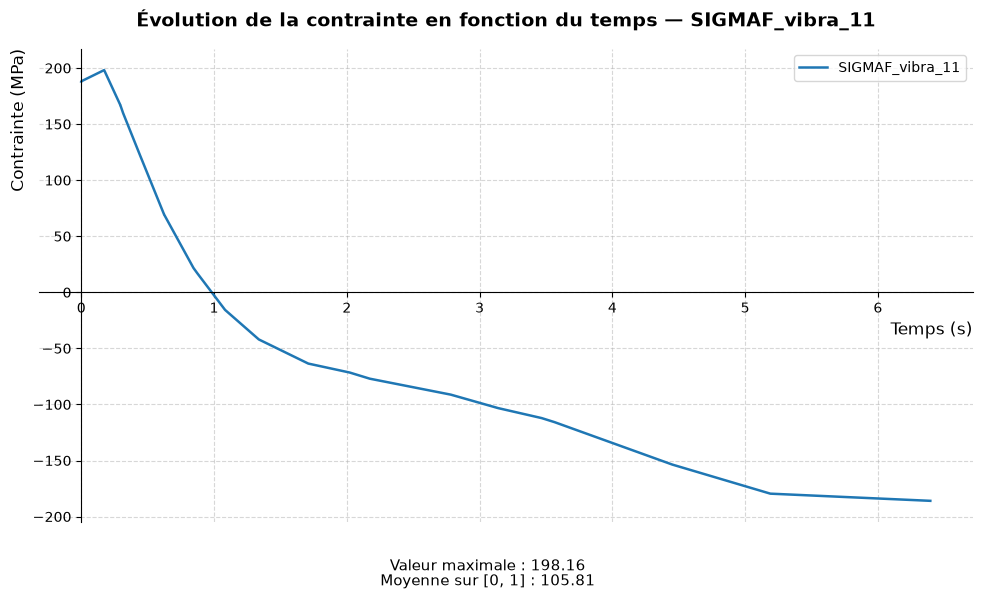

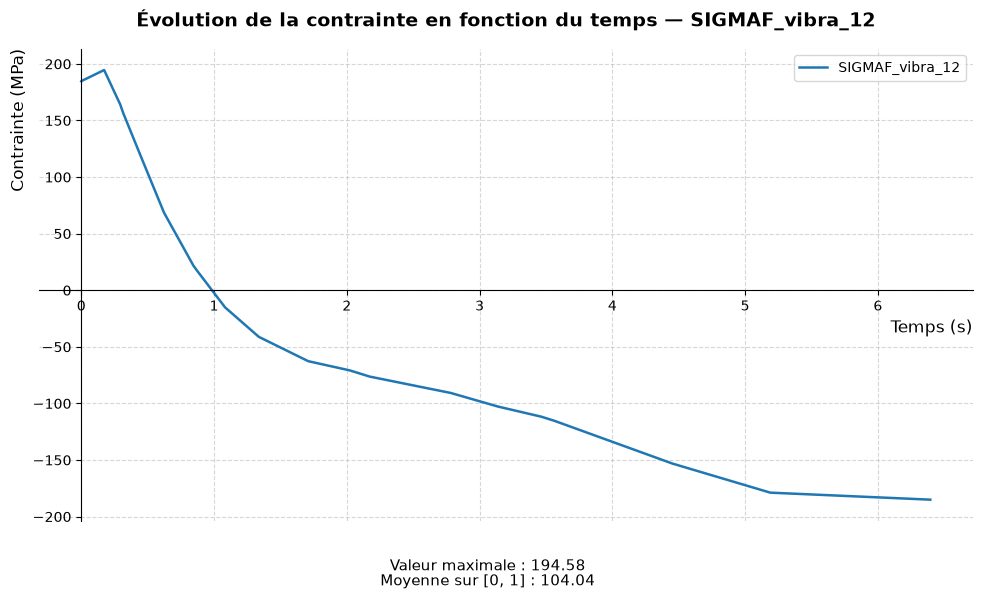

In [39]:
dossier_sortie_individuel.mkdir(exist_ok=True)

for nom_fichier, data in jeux_de_donnees:
    x = data[:, 0]
    colonnes_y = data[:, 1:]
    nom_base = noms_personnalises.get(nom_fichier, nom_fichier)

    for i in range(colonnes_y.shape[1]):
        fig, ax = plt.subplots(figsize=(10, 6))

        y_original = colonnes_y[:, i].astype(float).copy()
        valeur_max = np.nanmax(y_original)
        borne_debut, borne_fin = 0.0, 1.0
        if (np.all(np.isfinite(x)) and np.all(np.isfinite(y_original))
                and x[0] <= borne_debut and x[-1] >= borne_fin):
            x_interieur = x[(x > borne_debut) & (x < borne_fin)]
            x_integration = np.concatenate(([borne_debut], x_interieur, [borne_fin]))
            y_integration = np.interp(x_integration, x, y_original)
            aire = np.sum(np.diff(x_integration) * (y_integration[:-1] + y_integration[1:]) / 2)
            valeur_moyenne = aire / (borne_fin - borne_debut)
            texte_moyenne = f"Moyenne sur [0, 1] : {valeur_moyenne:.2f}"
        else:
            texte_moyenne = "Moyenne sur [0, 1] : non calculable (intervalle hors données)"
        y = y_original.copy()
        if enlever_zeros_y:
            y[np.abs(y) <= seuil_zero] = np.nan

        label = nom_base if colonnes_y.shape[1] == 1 else f"{nom_base} - Courbe {i + 1}"
        ax.plot(x, y, linewidth=1.8, label=label)

        valides = ~np.isnan(y)
        x_val = [x[valides]] if np.any(valides) else []
        y_val = [y[valides]] if np.any(valides) else []

        formater_graphique(ax, f"{titre} — {label}", x_val, y_val)

        fig.text(0.5, 0.04, f"Valeur maximale : {valeur_max:.2f}", ha="center", fontsize=11)
        fig.text(0.5, 0.015, texte_moyenne, ha="center", fontsize=11)
        plt.tight_layout(rect=(0, 0.09, 1, 1))
        nom_png = f"{nom_fichier}.png" if colonnes_y.shape[1] == 1 else f"{nom_fichier}_col{i + 1}.png"
        plt.savefig(dossier_sortie_individuel / nom_png, dpi=300)
        plt.show()
        plt.close(fig)